---
title: "3.5.b Amenaza por incendios de cobertura vegetal"
short_title: "b. Amenaza"
subtitle: "Focos de calor 2001–2025, pérdida de bosque y condiciones secas en el entorno de Leticia"
description: "Análisis de focos de calor de NASA FIRMS, pérdida de cobertura arbórea (Hansen) y meteorología seca alrededor de Leticia."
keywords: [incendios, FIRMS, MODIS, VIIRS, deforestación, Hansen, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/35_incendios/b_amenaza.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El bosque amazónico húmedo casi no arde de forma natural. El fuego llega con la **deforestación y las quemas
agrícolas** y se propaga cuando la sequía seca la hojarasca y el sotobosque. En 2024, el año de la vaciante
récord, la UNGRD registró en Leticia 14 incendios de cobertura vegetal, frente a uno o ninguno en años
anteriores (ver [1.7](../../01_conceptos/17_perfil_riesgos.ipynb)). Este cuaderno mide la amenaza con focos de
calor satelitales, la pérdida de bosque y las condiciones de sequía.

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from leticia import aoi, clima, espacial, exposicion, fuentes, riesgo, viz
from leticia.config import parametros

pi = parametros()["incendios"]
urbana = aoi.area_urbana()
mun = fuentes.limite_municipal()


def focos(sensor="modis", anios=None):
    f = fuentes.focos_calor(sensor, anios)
    if sensor == "modis":
        f = f[f["confidence"] >= pi["confianza_modis_min"]]
    else:
        f = f[f["confidence"].astype(str).str.lower().isin(pi["confianza_viirs"])]
    f = f[f["type"] == 0] if "type" in f else f          # solo vegetación (excluye fuentes estáticas y volcanes)
    return gpd.GeoDataFrame(f, geometry=gpd.points_from_xy(f.longitude, f.latitude), crs=4326)

## 1. Focos de calor por año y por mes

Focos MODIS 2001–2025: **13**; focos VIIRS 2012–2025: **82**. Año con más focos VIIRS: **2024** (16).

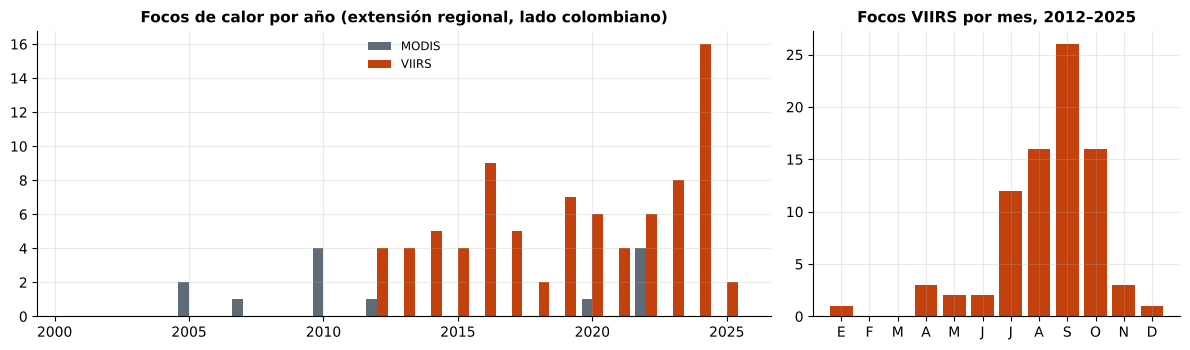

In [3]:
modis = focos("modis")
viirs = focos("viirs-snpp", list(range(2012, 2026)))
anual = pd.DataFrame({"MODIS (1 km)": modis.groupby(modis.index.year).size(),
                      "VIIRS (375 m)": viirs.groupby(viirs.index.year).size()}).reindex(range(2001, 2026)).fillna(0).astype(int)
anual.loc[anual.index < 2012, "VIIRS (375 m)"] = np.nan
mensual = viirs.groupby(viirs.index.month).size().reindex(range(1, 13), fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
x = anual.index.values
ax[0].bar(x - 0.2, anual["MODIS (1 km)"], width=0.4, color=viz.GRIS, label="MODIS")
ax[0].bar(x + 0.2, anual["VIIRS (375 m)"], width=0.4, color=viz.CALOR, label="VIIRS")
ax[0].set_title("Focos de calor por año (extensión regional, lado colombiano)")
ax[0].legend()
ax[1].bar(mensual.index, mensual, color=viz.CALOR)
ax[1].set_xticks(range(1, 13)); ax[1].set_xticklabels(list("EFMAMJJASOND"))
ax[1].set_title("Focos VIIRS por mes, 2012–2025")
fig.tight_layout()
display(Markdown(f"Focos MODIS 2001–2025: **{int(anual['MODIS (1 km)'].sum())}**; focos VIIRS 2012–2025: **{int(anual['VIIRS (375 m)'].sum())}**. "
                 f"Año con más focos VIIRS: **{int(anual['VIIRS (375 m)'].idxmax())}** ({int(anual['VIIRS (375 m)'].max())})."))

In [4]:
viz.pie(viz.nota_fuente("focos_calor") + " Giglio et al. (2016); Schroeder et al. (2014).")

*Fuente: NASA FIRMS — Archivo anual por país, MODIS (1 km, 2001–) y VIIRS S-NPP (375 m, 2012–). Giglio et al. (2016); Schroeder et al. (2014).*

**Lectura.** Comparado con el arco de deforestación de Brasil o con el piedemonte colombiano, el entorno de
Leticia tiene **pocos focos detectables**: los incendios son pequeños (quemas de rastrojo y potreros, fuegos de
sotobosque) y muchos escapan a sensores de 375 m–1 km. A escala mundial, contar los fuegos pequeños que no dejan
cicatriz visible en los productos de área quemada de 500 m aumenta el área quemada en cerca de 35 %
[@randerson2012]: los conteos de este cuaderno son un **mínimo**. Aun así, los años de sequía sobresalen, en especial 2024,
cuando la UNGRD registró 14 incendios de cobertura vegetal en el municipio. ThinkHazard clasifica la amenaza por
incendio forestal de Leticia como **baja** [@thinkhazard2024].

## 2. Dónde ocurren

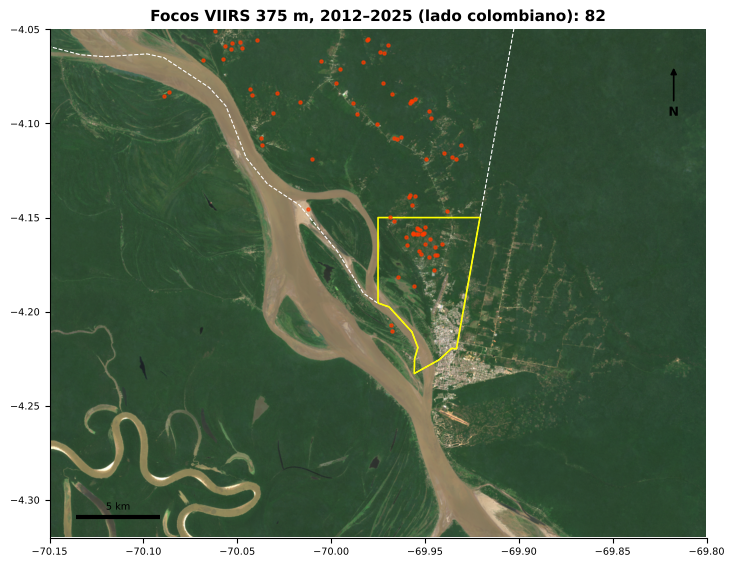

In [5]:
fig, ax = plt.subplots(figsize=(9, 6.6))
viz.fondo(ax, "bbox_regional")
mun.boundary.plot(ax=ax, color="white", lw=0.8, ls="--", zorder=2)
urbana.to_crs(4326).boundary.plot(ax=ax, color="yellow", lw=1.2, zorder=3)
if len(viirs):
    viirs.plot(ax=ax, markersize=5, color="#ff3b00", alpha=0.7, zorder=4)
viz.marco(ax, "bbox_regional", f"Focos VIIRS 375 m, 2012–2025 (lado colombiano): {len(viirs)}")

Los focos se alinean con la **vía Leticia–Tarapacá** y los caminos que salen de ella, donde avanza la frontera
agropecuaria, y con la periferia urbana. El archivo por país de FIRMS solo incluye focos en territorio
colombiano: los de Brasil y Perú, que también aportan humo, no aparecen en el mapa.

## 3. Pérdida de cobertura arbórea

Pérdida acumulada 2001–2024 en la extensión regional dentro de Colombia: **2.918 ha**; últimos cinco años: 819 ha.

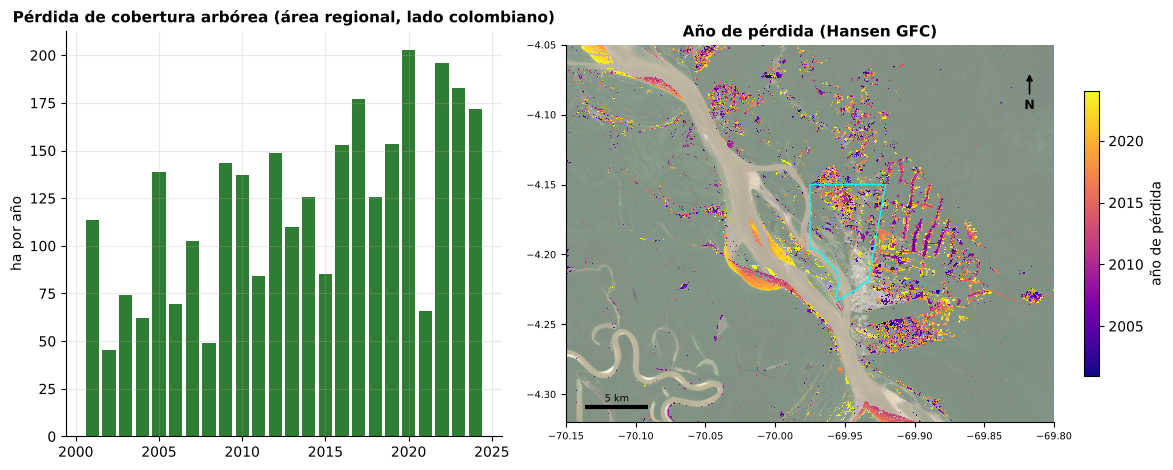

In [6]:
loss = fuentes.bosque_hansen("lossyear")
tc = fuentes.bosque_hansen("treecover2000")
dentro = loss.rio.write_crs(4326).rio.clip(mun.geometry, drop=False)
px_ha = (0.00025 * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4
por_anio = pd.Series(dentro.values.ravel()).value_counts().drop(0, errors="ignore").sort_index() * px_ha
por_anio.index = por_anio.index.astype(int) + 2000
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].bar(por_anio.index, por_anio, color=viz.VERDE)
ax[0].set_ylabel("ha por año")
ax[0].set_title("Pérdida de cobertura arbórea (área regional, lado colombiano)")
viz.fondo(ax[1], "bbox_regional", alfa=0.6)
v = loss.where(loss > 0)
im = ax[1].imshow(v.values + 2000, extent=(float(loss.x.min()), float(loss.x.max()), float(loss.y.min()), float(loss.y.max())), cmap="plasma",
                  vmin=2001, vmax=2024, zorder=2, interpolation="nearest")
urbana.to_crs(4326).boundary.plot(ax=ax[1], color="cyan", lw=1, zorder=3)
fig.colorbar(im, ax=ax[1], shrink=0.7, label="año de pérdida")
viz.marco(ax[1], "bbox_regional", "Año de pérdida (Hansen GFC)")
fig.tight_layout()
display(Markdown(f"Pérdida acumulada 2001–2024 en la extensión regional dentro de Colombia: **{por_anio.sum():,.0f} ha**; "
                 f"últimos cinco años: {por_anio.loc[2020:].sum():,.0f} ha.".replace(",", ".")))

In [7]:
viz.pie(viz.nota_fuente("perdida_bosque") + " Hansen et al. (2013).")

*Fuente: Hansen et al. / University of Maryland – Global Forest Change — GFC v1.12 (2001–2024): treecover2000, lossyear. Hansen et al. (2013).*

## 4. Sequía y fuego

Correlación de Spearman entre focos anuales y SPEI-3 de octubre (2012–2025): **-0.54**.

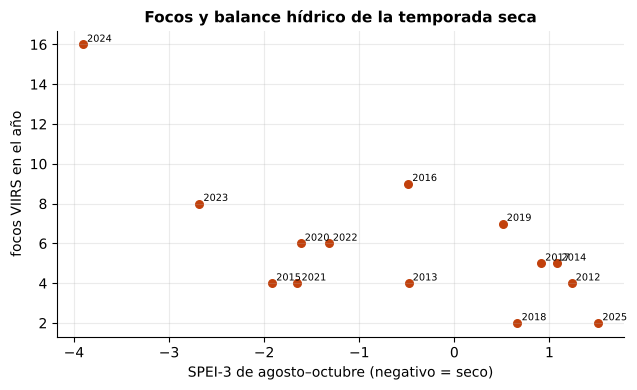

In [8]:
era = fuentes.clima_diario().loc["2001":]
spei3 = clima.balance_hidrico_spei(era["precipitation_sum"], era["et0_fao_evapotranspiration"], 3, base=(2001, 2020))
spei_sep = spei3[spei3.index.month == 10]
spei_sep.index = spei_sep.index.year
df = pd.concat({"focos_viirs": anual["VIIRS (375 m)"], "spei3_oct": spei_sep}, axis=1).dropna()
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(df["spei3_oct"], df["focos_viirs"], color=viz.CALOR, s=30)
for a, r_ in df.iterrows():
    ax.annotate(str(a), (r_["spei3_oct"], r_["focos_viirs"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("SPEI-3 de agosto–octubre (negativo = seco)")
ax.set_ylabel("focos VIIRS en el año")
ax.set_title("Focos y balance hídrico de la temporada seca")
fig.tight_layout()
r = df.corr(method="spearman").iloc[0, 1]
display(Markdown(f"Correlación de Spearman entre focos anuales y SPEI-3 de octubre (2012–2025): **{r:.2f}**."))

**Lectura.** Los años con temporada seca más deficitaria tienden a tener más focos. La relación entre sequía, deforestación y fuego es la sinergia
que el Panel Científico por la Amazonía identifica como el mayor riesgo para el bosque y la salud: el humo de
2023–2024 afectó la calidad del aire en ciudades de toda la cuenca [@costa2023spa; @marengo2024spa].